In [18]:
# 1. Import Library

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

In [20]:
# 2. Load the Iris dataset

iris = load_iris()

X = iris.data # Features
y = iris.target #target


class_names=iris.target_names

In [3]:
# 3. Split the dataset

X_train, X_test, y_train, y_test = train_test_split (X, y , test_size=0.2, random_state = 42)

print("Training samples:" , X_train.shape[0])
print("Testing samples:" , X_test.shape[0])

Training samples: 120
Testing samples: 30


In [4]:
# 4. Define all classifier

models ={
    "kNN": KNeighborsClassifier(n_neighbors=3),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "SVM": SVC(kernel='rbf', random_state=42),
    "Naive Bayes": GaussianNB()
}

In [6]:
# 5.Train Models
for name, model in models.items():
    model.fit(X_train, y_train)

In [22]:
#6. Confusion matrix plot function

def plot_conf_matrix(ax, y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

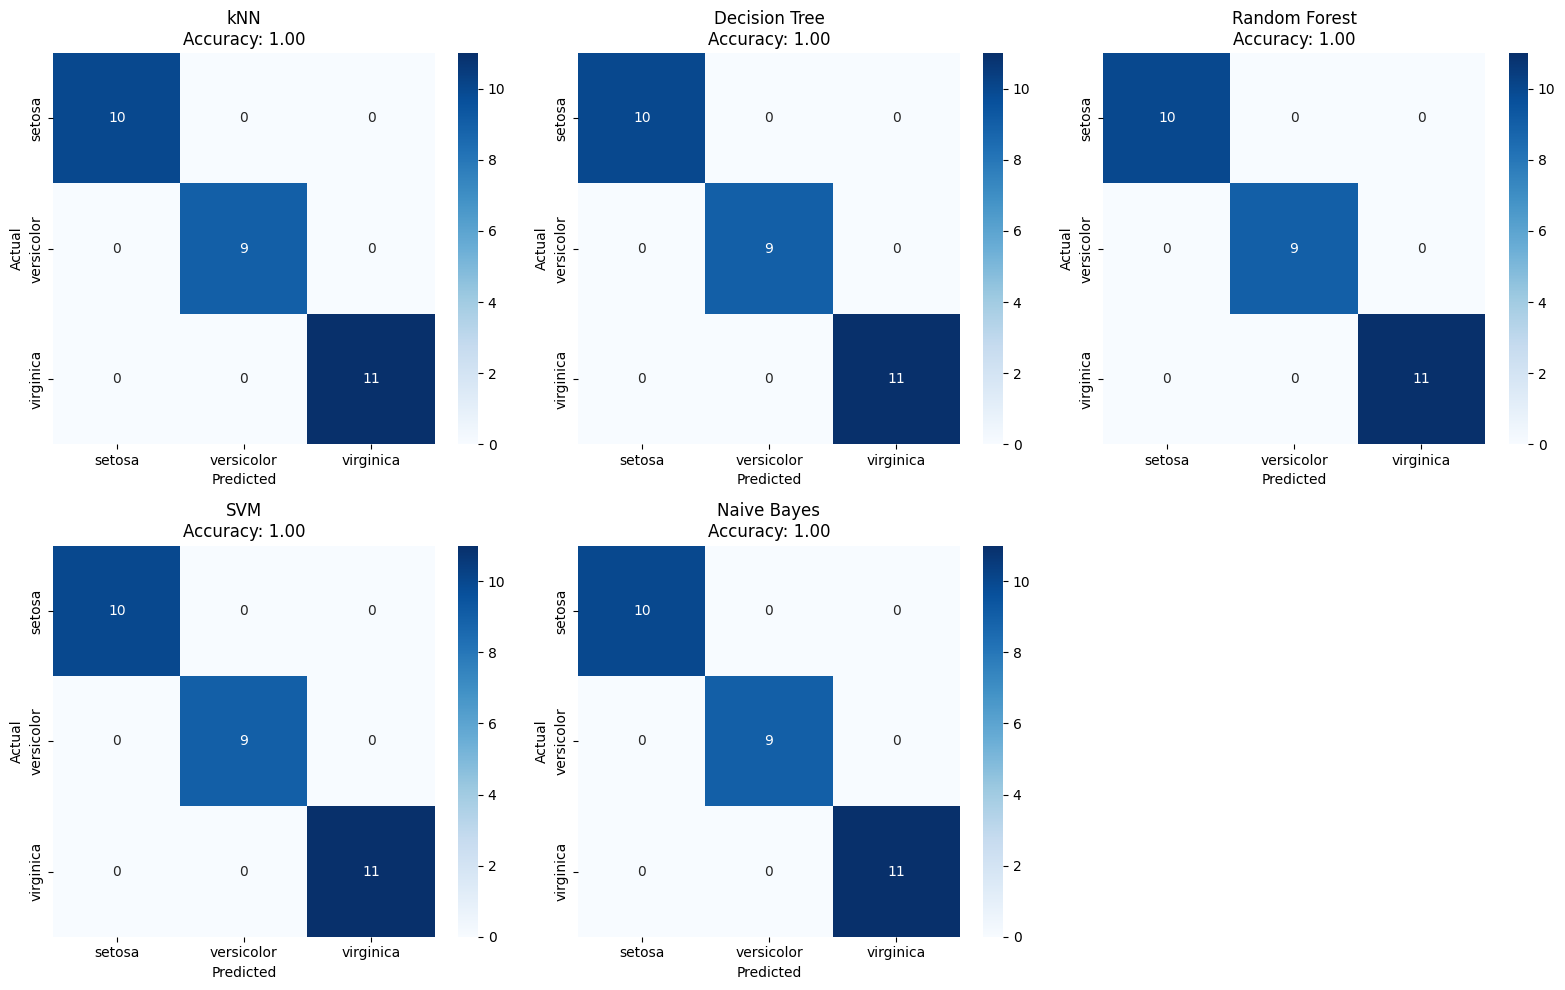

In [24]:
# 7. Plot confusion matrix for all model

fig, axes = plt.subplots(2, 3, figsize=(16,10))
axes = axes.ravel()

for i, (name, model) in enumerate(models.items()):
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)

    plot_conf_matrix(
        axes[i],
        y_test,
        y_pred,
        f"{name}\nAccuracy: {acc:.2f}"
    )

#Remove empty subplot
fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()

In [28]:
# 8. Compute Performance Metrics from Confusions Matrix

from sklearn.metrics import precision_score, recall_score, f1_score

def compute_metrics(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average ='macro')
    recall = recall_score(y_true, y_pred, average='macro')
    f1= f1_score(y_true, y_pred, average='macro')

    return cm, accuracy, precision, recall, f1

In [30]:
#9. Evaluate all models

results ={}

for name, model in models.items():
    y_pred = model.predict(X_test)

    cm, acc, prec, rec, f1 = compute_metrics(y_test, y_pred)

    results[name] = {
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-score": f1
    }


In [31]:
#10 Display Result
for model_name, metrics in results.items():
    print(f"\n{model_name}")
    for metric_name, value in metrics.items():
        print(f"{metric_name}: {value:4f}")


kNN
Accuracy: 1.000000
Precision: 1.000000
Recall: 1.000000
F1-score: 1.000000

Decision Tree
Accuracy: 1.000000
Precision: 1.000000
Recall: 1.000000
F1-score: 1.000000

Random Forest
Accuracy: 1.000000
Precision: 1.000000
Recall: 1.000000
F1-score: 1.000000

SVM
Accuracy: 1.000000
Precision: 1.000000
Recall: 1.000000
F1-score: 1.000000

Naive Bayes
Accuracy: 1.000000
Precision: 1.000000
Recall: 1.000000
F1-score: 1.000000


In [32]:
# 11. Convert to Dataframe(clean table)
import pandas as pd 
df_results = pd.DataFrame(results).T
print(df_results)

               Accuracy  Precision  Recall  F1-score
kNN                 1.0        1.0     1.0       1.0
Decision Tree       1.0        1.0     1.0       1.0
Random Forest       1.0        1.0     1.0       1.0
SVM                 1.0        1.0     1.0       1.0
Naive Bayes         1.0        1.0     1.0       1.0


In [35]:
# 12. Predict with unknown data 

unknown_sample = np.array([[5.1, 3.5, 1.4, 0.2]])

print("Predictions for unknown sample:", unknown_sample[0])

for name, model in models.items():
    prediction = model.predict(unknown_sample)
    predicted_class = iris.target_names[prediction[0]]
    print(f"{name} -> {predicted_class}")

Predictions for unknown sample: [5.1 3.5 1.4 0.2]
kNN -> setosa
Decision Tree -> setosa
Random Forest -> setosa
SVM -> setosa
Naive Bayes -> setosa
